<div dir="rtl">

# ניתוח רשתות תורים בעזרת סימולציה

### במחברת הזאת נדגים אופטימיזציה של מערכות תורים בעזרת סימולציה.

### כל הדוגמאות במחברת הן לא מרקוביות:

### - זמני הביניים בין הגעות נוצרים כמימושים מראש, ולא מניחים שהם אקספוננציאליים.
### - זמני השירות נוצרים כמימושים מראש, ולא מניחים שהם אקספוננציאליים.
### - כל המדדים והתוצאות שמוצגים במחברת מגיעים מהרצות סימולציה.
### - לא משתמשים בנוסחאות סגורות של מודלי תורים מרקוביים כדי לקבל את התוצאות.

### המטרה היא להראות תהליך עבודה פרקטי:

### 1. מגדירים את ארכיטקטורת מערכת התורים.
### 2. מגדירים מה מותר לשנות ומה רוצים לאפטם.
### 3. מגרילים מראש את אותם קלטים לכל החלופות.
### 4. מריצים סימולציה לכל חלופה.
### 5. משווים מדדים סימולטיביים ובוחרים את התכנון הטוב ביותר.

</div>


In [1]:
import sys
import importlib

sys.path.append("../../code")

import utils
importlib.reload(utils)

from utils import (
    draw_queue_optimization_network,
    evaluate_server_mix_optimization,
    evaluate_split_proportion_optimization,
    evaluate_throughput_capacity_optimization,
    plot_server_mix_results,
    plot_split_proportion_results,
    plot_throughput_optimization_results,
)


<div dir="rtl">

## דוגמה 1: אופטימיזציה של פרופורציות זרימה

### ארכיטקטורה:  ראו גרף
### שאלה עסקית:

### איזה אחוז מהלקוחות כדאי לשלוח ל-`S1`?

### משתנה החלטה:

### $p$ = הפרופורציה שנשלחת ל-`S1`.
### $1-p$ = הפרופורציה שנשלחת ל-`S2`.

### מבנה הניסוי הסימולטיבי:

### זמני הביניים בין ההגעות נוצרים פעם אחת.
### זמני השירות ב-`S1` וב-`S2` נוצרים פעם אחת.
### עבור כל ערך מועמד של $p$, משתמשים באותם קלטים שהוגרלו מראש.
### כך ההשוואה בין החלטות הניתוב נקייה יותר.

### פונקציית המטרה:

### למזער את זמן ההמתנה הממוצע שמתקבל בסימולציה.
### כלומר, אם $\widehat{W}_q(p)$ הוא זמן ההמתנה הממוצע בסימולציה עבור פיצול $p$, אז הבעיה היא:
### $\min_p \widehat{W}_q(p)$

### מדד נוסף שנחשב:

### בנוסף לממוצע נחשב גם את אחוזון 90 של זמן ההמתנה.
### נסמן אותו $\widehat{q}_{0.9}(p)$.
### זהו זמן המתנה שרק כ-10% מהלקוחות מחכים יותר ממנו.
### המדד הזה לא מחליף את פונקציית המטרה כאן, אלא עוזר לבדוק האם פתרון שטוב בממוצע טוב גם עבור לקוחות שמחכים הרבה יחסית.

</div>


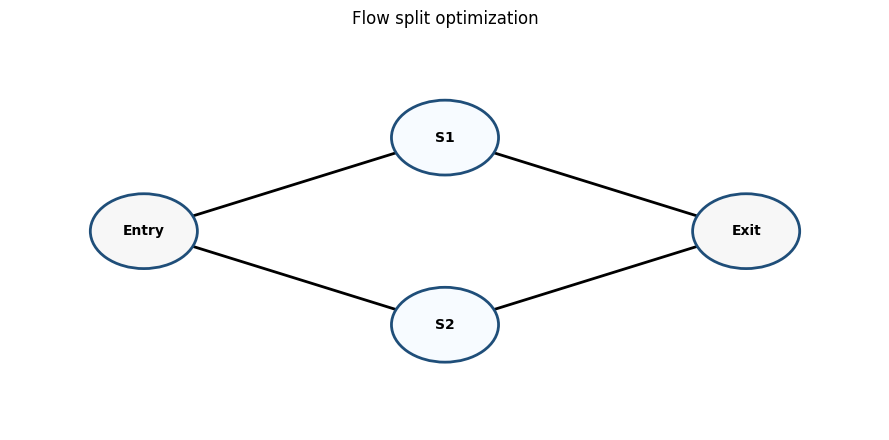

In [2]:
draw_queue_optimization_network("split")


In [2]:
split_result = evaluate_split_proportion_optimization(
    num_customers=2_500,
    seed=2026,
)

split_result["input_summary"]


,input,distribution,sample_mean
0,inter-arrival,lognormal,0.925161
1,service S1,lognormal,0.758724
2,service S2,lognormal,1.164663


<div dir="rtl">

## תוצאות הסימולציה: פיצול זרימה

### הטבלה הבאה מציגה את פרופורציות הפיצול הטובות ביותר לפי הסימולציה.

### בטבלה מופיעים שני מדדי זמן המתנה:

### `mean_waiting_time` הוא זמן ההמתנה הממוצע, ולפיו בוחרים את הפיצול האופטימלי בדוגמה הזאת.
### `p90_waiting_time` הוא אחוזון 90 של זמן ההמתנה, והוא משמש כמדד משלים לזנב ההתפלגות.

### נקודה חשובה:

### התחנה שנראית מהירה יותר אינה בהכרח צריכה לקבל את כל הלקוחות.
### אם שולחים יותר מדי זרימה לתחנה אחת, היא עלולה להפוך לצוואר בקבוק.
### הסימולציה עוזרת למצוא את האיזון הטוב ביותר בין התחנות.
### אחר כך אפשר לבדוק האם אותו איזון נראה טוב גם לפי אחוזון 90.

</div>


In [3]:
split_result["results"].sort_values("mean_waiting_time").head(8)


,split_to_S1,split_to_S2,mean_waiting_time,p90_waiting_time,mean_system_time,visits_S1,visits_S2
11,0.60,0.40,0.708657,2.171433,1.634530,1494,1006
12,0.65,0.35,0.736140,2.351875,1.641346,1613,887
10,0.55,0.45,0.783110,2.528474,1.725771,1360,1140
13,0.70,0.30,0.814236,2.465196,1.699966,1745,755
14,0.75,0.25,0.938035,2.861702,1.800118,1874,626
9,0.50,0.50,1.014854,3.131175,1.978687,1247,1253
15,0.80,0.20,1.025175,3.091388,1.865031,1999,501
8,0.45,0.55,1.204944,3.825068,2.184283,1130,1370


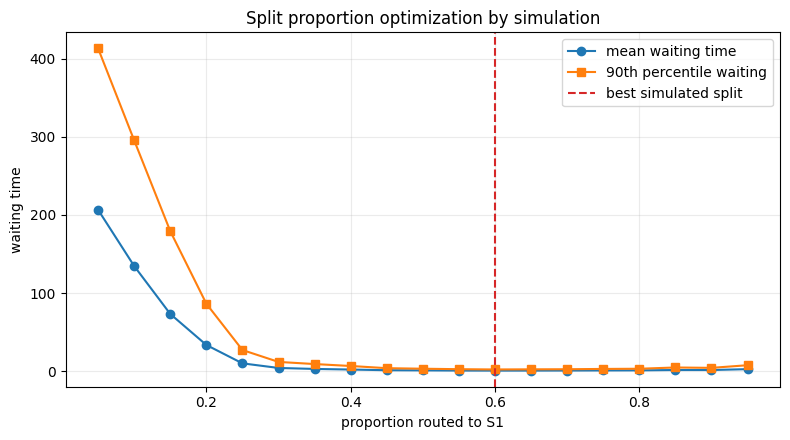

In [4]:
plot_split_proportion_results(split_result)


In [6]:
split_result["best"]


split_to_S1             0.600000
split_to_S2             0.400000
mean_waiting_time       0.708657
p90_waiting_time        2.171433
mean_system_time        1.634530
visits_S1            1494.000000
visits_S2            1006.000000
Name: 11, dtype: float64

<div dir="rtl">

## פירוש התוצאות: פיצול זרימה

### הפרופורציה הטובה ביותר נמצאה בעזרת סימולציה, ולא בעזרת נוסחה סגורה.

### עבור כל ערך של $p$:

### 1. הלקוחות מגיעים לפי אותם מימושי זמני ביניים בין הגעות.
### 2. כל לקוח מנותב לפי ההסתברות $p$.
### 3. כל תחנה משתמשת במימושי זמני השירות שלה.
### 4. הסימולציה מתעדת את זמני ההמתנה.
### 5. מחשבים גם ממוצע זמן המתנה וגם אחוזון 90 של זמן ההמתנה.
### 6. בוחרים את הפיצול עם זמן ההמתנה הממוצע הנמוך ביותר.
### 7. בודקים האם אחוזון 90 תומך באותה החלטה, או שהוא מצביע על בעיה בזנב ההתפלגות.

### למה זה מעניין?

### לפעמים שתי חלופות דומות מאוד בממוצע, אבל באחת מהן יש קבוצה קטנה של לקוחות שמחכה הרבה מאוד.
### במקרה כזה אחוזון 90 יכול להראות שהפתרון שנראה טוב לפי ממוצע בלבד אינו בהכרח הפתרון הרצוי מבחינת איכות שירות.

</div>


<div dir="rtl">

## דוגמה 2: אופטימיזציה של תמהיל שרתים איטיים ומהירים

### ארכיטקטורה:
### תור FIFO יחיד מזין מאגר שרתים לא הומוגני.
### יש שני סוגי שרתים:
### שרת איטי: זול יותר, אבל זמן השירות שלו ארוך יותר בממוצע.
### שרת מהיר: יקר יותר, אבל זמן השירות שלו קצר יותר בממוצע.

### שאלה עסקית:
### איזה שילוב של שרתים איטיים ומהירים כדאי לבחור תחת מגבלת תקציב?

### משתני החלטה:
### $c_s$ = מספר השרתים האיטיים.
### $c_f$ = מספר השרתים המהירים.

### פרמטרים של הבעיה:
### $K_s$ = עלות שרת איטי אחד.
### $K_f$ = עלות שרת מהיר אחד.
### $B$ = התקציב הכולל.
### $h$ = עלות יחידת זמן המתנה ממוצעת של לקוח.
### $\widehat{W}_q(c_s,c_f)$ = זמן ההמתנה הממוצע בתור שמתקבל מסימולציה עבור התמהיל $(c_s,c_f)$.

### אילוץ התקציב:
### $K_s c_s + K_f c_f \le B$

### אילוץ שלמות:
### $c_s,c_f \in \{0,1,2,\ldots\}$

### אילוץ תפעולי בסיסי:
### $c_s+c_f \ge 1$

### פונקציית המטרה:
### $\min_{c_s,c_f} J(c_s,c_f)=K_s c_s+K_f c_f+h\widehat{W}_q(c_s,c_f)$

### כלומר, אנחנו מאזנים בין שני כוחות:
### מצד אחד, יותר שרתים ובעיקר שרתים מהירים עולים יותר כסף.
### מצד שני, מעט מדי קיבולת מגדילה את זמן ההמתנה, ולכן מגדילה את עלות ההמתנה.
### את $\widehat{W}_q(c_s,c_f)$ לא מחשבים מנוסחה סגורה, אלא מתוך הסימולציה.

### גם כאן כל זמני ההגעה והשירות הם מימושים שהוגרלו מראש.
### לכן כל תמהיל שרתים נבדק על אותו תרחיש בסיסי, וההשוואה בין חלופות הוגנת יותר.

</div>


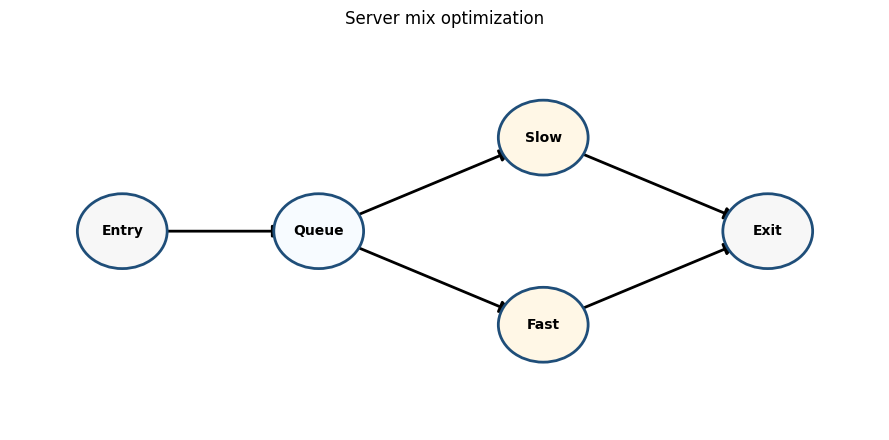

In [7]:
draw_queue_optimization_network("server_mix")


In [8]:
server_mix_result = evaluate_server_mix_optimization(
    num_customers=2_500,
    seed=3030,
)

server_mix_result["input_summary"]


,input,distribution,sample_mean
0,inter-arrival,lognormal,0.330975
1,slow service,lognormal,1.449125
2,fast service,lognormal,0.548887


<div dir="rtl">

## תוצאות הסימולציה: תמהיל שרתים

### כל שורה בטבלה היא תכנון אפשרי שעומד בתקציב.

### פונקציית המטרה משלבת:

### עלות כוח אדם.
### זמן המתנה ממוצע שהתקבל בסימולציה.

### הדוגמה בנויה כך שהתשובה אינה טריוויאלית:

### רק שרתים איטיים הם זולים, אבל עלולים ליצור המתנה ארוכה.
### רק שרתים מהירים נותנים שירות טוב, אבל הם יקרים.
### תכנון מעורב יכול להיות הפתרון הטוב ביותר.

</div>


In [9]:
server_mix_result["results"].head(10)

,slow_servers,fast_servers,staffing_cost,mean_waiting_time,p90_waiting_time,objective
0,3,1,12,0.484209,1.455568,13.452627
1,0,2,12,0.626926,1.634399,13.880778
2,5,0,10,1.314255,3.860451,13.942765
3,2,1,10,2.364323,5.050777,17.092970
4,4,0,8,43.585596,77.263740,138.756787
5,1,1,8,86.407778,152.646480,267.223335
6,3,0,6,191.197906,345.949230,579.593717
7,0,1,6,267.644154,484.770586,808.932461
8,2,0,4,491.086256,887.756048,1477.258768
9,1,0,2,1396.627535,2517.800547,4191.882606


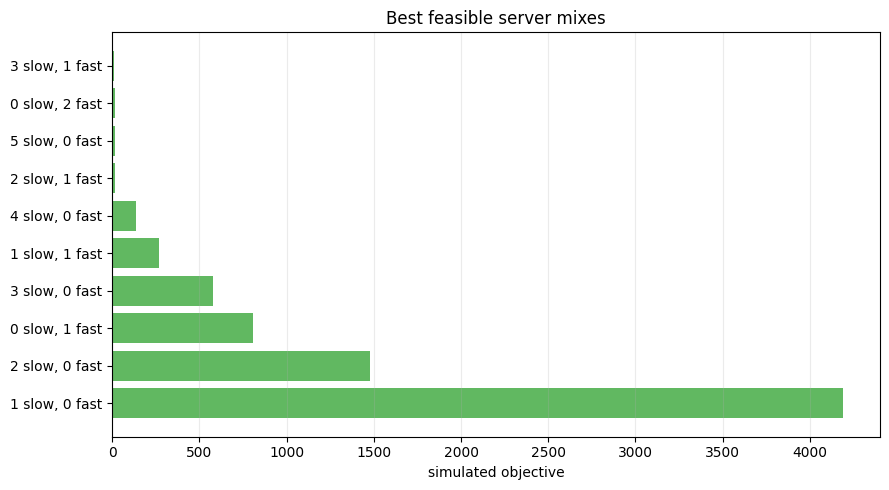

In [10]:
plot_server_mix_results(server_mix_result)


In [11]:
server_mix_result["best"]


slow_servers          3.000000
fast_servers          1.000000
staffing_cost        12.000000
mean_waiting_time     0.484209
p90_waiting_time      1.455568
objective            13.452627
Name: 0, dtype: float64

<div dir="rtl">

## פירוש התוצאות: תמהיל שרתים

### זו בעיית אופטימיזציה עם אילוץ תקציב.

### עבור כל שילוב אפשרי:

### 1. משתמשים באותם מימושי הגעה.
### 2. מגרילים מראש זמני שירות לשרתים איטיים ומהירים.
### 3. מריצים סימולציה של תור FIFO עם שרתים לא הומוגניים.
### 4. מודדים את זמני ההמתנה שהתקבלו.
### 5. מחברים עלות כוח אדם ועלות המתנה.

### התכנון הטוב ביותר הוא התכנון שעומד באילוץ ונותן את ערך המטרה הסימולטיבי הנמוך ביותר.

</div>


<div dir="rtl">

## דוגמה 3: מקסום תפוקה במערכת ייצור רוויה

### ארכיטקטורה:

### `Raw material -> S1 -> S2/S3 -> S4 -> Exit`

### אין כאן התפלגות הגעה חיצונית.
### לפני `S1` יש מלאי חומרי גלם אינסופי.
### לכן ברגע ששרת ב-`S1` מתפנה, הוא יכול להתחיל מיד מוצר חדש.

### שאלה עסקית:

### איך כדאי לחלק מספר כולל קבוע של שרתים בין התחנות כדי לייצר כמה שיותר מוצרים בזמן נתון?

### משתני החלטה:

### $c_1,c_2,c_3,c_4$ = מספר השרתים בתחנות `S1,S2,S3,S4`.

### אילוץ:

### $c_1+c_2+c_3+c_4=7$

### פונקציית המטרה הסימולטיבית:

### למקסם את מספר המוצרים שיוצאים מ-`S4` עד סוף אופק הסימולציה.
### אם $N_{out}(T)$ הוא מספר המוצרים שהושלמו עד זמן $T$, אז:
### $\max_{c_1,c_2,c_3,c_4} \frac{N_{out}(T)}{T}$

### כאן התפוקה אינה מוגבלת על ידי ביקוש חיצוני.
### היא מוגבלת על ידי קיבולת התחנות, זמני השירות, הפיצול בין `S2` ו-`S3`, וצווארי הבקבוק שנוצרים ברשת.

</div>


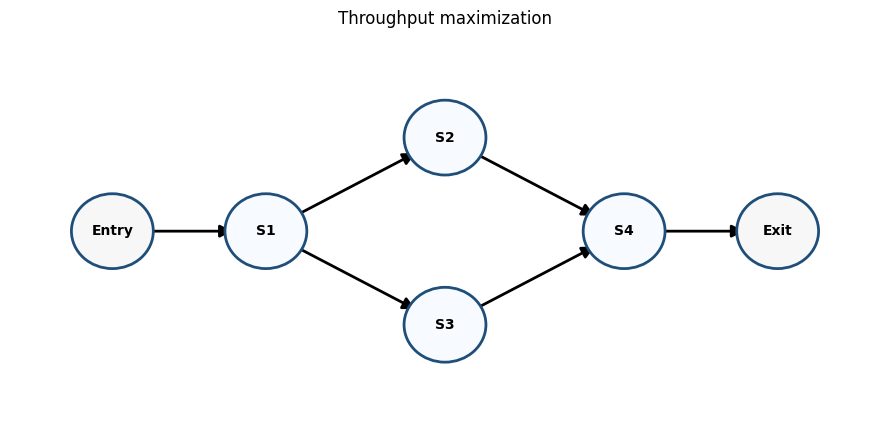

In [6]:
draw_queue_optimization_network("throughput")


In [2]:
throughput_result = evaluate_throughput_capacity_optimization(
    seed=4040,
    production_horizon=15_000,
    total_servers=7,
)

throughput_result["input_summary"]


,input,distribution,sample_mean
0,raw material before S1,infinite inventory,NaN
1,service S1,lognormal,0.620347
2,service S2,lognormal,0.950106
3,service S3,lognormal,0.849878
4,service S4,lognormal,0.900977


<div dir="rtl">

## תוצאות הסימולציה: מקסום תפוקה

### כל שורה בטבלה היא הקצאת שרתים אחרת.

### העמודות `S1_servers`, `S2_servers`, `S3_servers`, ו-`S4_servers` מתארות את הארכיטקטורה שנבדקה.

### המדד המרכזי הוא תפוקה סימולטיבית:

### מספר המוצרים שהושלמו ב-`S4` עד סוף אופק הסימולציה, חלקי אורך האופק.

### בניגוד למערכת עם קצב הגעה חיצוני, כאן תמיד יש חומר גלם שמחכה לפני `S1`.
### לכן הקצאות שרתים שונות יכולות ליצור תפוקה שונה גם כאשר מריצים סימולציה ארוכה.

</div>


In [3]:
throughput_result["results"].head(12)

,S1_servers,S2_servers,S3_servers,S4_servers,jobs_started,completed_by_horizon,throughput,work_in_process_at_horizon,mean_waiting_time
0,2,2,1,2,48358,33623,2.241533,14735,677.533459
1,2,1,2,2,48358,33620,2.241333,14738,627.274497
2,2,1,1,3,48358,33591,2.239400,14767,627.260108
3,3,1,1,2,72606,33493,2.232867,39113,958.255253
4,1,2,1,3,24105,24099,1.606600,6,0.175123
5,1,2,2,2,24105,24099,1.606600,6,0.202953
6,1,3,1,2,24105,24099,1.606600,6,0.323619
7,1,1,2,3,24105,24094,1.606267,11,0.784871
8,1,1,1,4,24105,24094,1.606267,11,0.893689
9,1,1,3,2,24105,24094,1.606267,11,0.976659


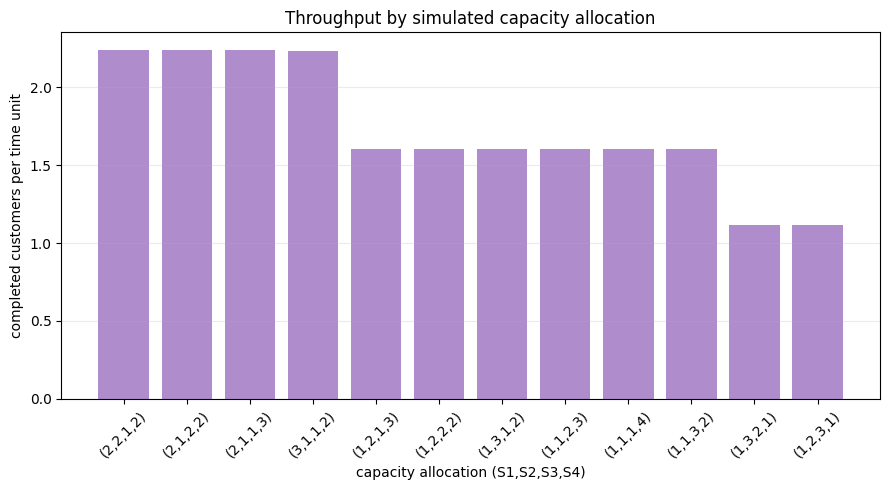

In [4]:
plot_throughput_optimization_results(throughput_result)


In [16]:
throughput_result["best"]


S1_servers                       2.000000
S2_servers                       1.000000
S3_servers                       1.000000
S4_servers                       3.000000
jobs_started                  4851.000000
completed_by_horizon          3398.000000
throughput                       2.265333
work_in_process_at_horizon    1453.000000
mean_waiting_time               67.010336
Name: 0, dtype: float64

<div dir="rtl">

## פירוש התוצאות: תפוקה

### ההקצאה הטובה ביותר אינה בהכרח ההקצאה שמוסיפה הכי הרבה שרתים לתחנה הראשונה.

### מדוע?

### במערכת הזאת `S1` תמיד יכול לעבוד, כי יש לפניו מלאי אינסופי.
### אבל אם `S2`, `S3`, או `S4` לא מקבלות מספיק שרתים, המוצרים ייתקעו בהמשך הקו.
### במקרה כזה הגדלת הקיבולת ב-`S1` רק מגדילה את כמות העבודה שנמצאת בתוך המערכת, ולא בהכרח את קצב היציאה.
### התפוקה נקבעת על ידי האיזון בין כל התחנות, ולא על ידי התחנה הראשונה בלבד.

### עבור כל הקצאת שרתים:

### 1. אין מימושי הגעה חיצוניים.
### 2. יש מלאי חומרי גלם אינסופי לפני `S1`.
### 3. כל תחנה משתמשת בזמני שירות לא מרקוביים שהוגרלו מראש.
### 4. מריצים את קו הייצור עד זמן $T$.
### 5. סופרים כמה מוצרים השלימו שירות ב-`S4`.
### 6. מחשבים תפוקה סימולטיבית: $N_{out}(T)/T$.
### 7. בוחרים את הקצאת השרתים עם התפוקה הסימולטיבית הגבוהה ביותר.

</div>


<div dir="rtl">

## סיכום

### במחברת הזאת ראינו שלוש בעיות אופטימיזציה במערכות תורים בעזרת סימולציה:

### 1. אופטימיזציה של פרופורציות זרימה.
### 2. אופטימיזציה של תמהיל שרתים איטיים ומהירים תחת תקציב.
### 3. מקסום תפוקה במערכת ייצור רוויה עם מלאי חומר גלם אינסופי.

### המבנה המשותף לכל הדוגמאות הוא:

### הארכיטקטורה קבועה.
### משתני ההחלטה מוגדרים במפורש.
### הקלטים נוצרים מראש לפני הסימולציה.
### כל חלופה נבדקת על ידי סימולציה.
### התכנון הטוב ביותר נבחר לפי מדדים סימולטיביים.

### זהו הרעיון המרכזי של ניתוח מערכות תורים בעזרת סימולציה.

</div>
